In [3]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time



<div dir="rtl">

## סימולציה בעזרת Python class

### כעת  נעשה סימולציה רגילה - רק נגדיר class שהוא ירכז את כל המידע שאנחנו צריכים
    
### זה יהיה ממש נוח בהמשך שנעשה סימולציות יותר מורכבות וכל האינפורמציה תחת אובייקט אחד

## רק תזכורת על classes בpython:

### 1. class יש לו תכונות ופונקציות. אני יכול לאתחל אובייקט עם תכונות מסוימות והפעיל עליהן פונצקיות. 

#### במקרה שלנו אני יכול לאתחל תור עם שרת יחיד. התכונות שלו יהיו: סביבת SimPy, שרתים, התפלגות הגעה, התפלגות שירות

### פונקציות שלנו יהיו: בלוקי שירות, הגעה ופונקציית run ששייכת לSimpy שאיתה מתחילים להריץ את הסימולציה

### נראה למטה איך זה עובד:

In [4]:
class Queue_example:
    
    #########################################################
    #################  Initiate system ###################### 
    #########################################################    
    
    def __init__(self, lamda, mu, sim_time):
        
        # Defining the simpy enviroment
        self.env = simpy.Environment()
        # Defining the simpy server
        self.server = simpy.Resource(self.env, capacity=1)
        # defining arrival rate
        self.lamda = lamda
        # defining service rate
        self.mu = mu
        
        self.id_customer = 0

        # Defining the end time of the simulation
        self.end_time = sim_time
        

    #########################################################
    ################# Run function ########################## 
    ######################################################### 
    
    def run(self):
        # defining the process
        self.env.process(self.customer_arrivals())
        # Executing the process
        self.env.run(until=self.end_time)

    
    #########################################################
    ################# Service Block ########################## 
    ######################################################### 
    
    
    def service(self, id_customer):
        
        # tracking the arrival time
        arrival_time = self.env.now
        
        # opening a with statement
        with self.server.request() as req:
            
            yield req
            
            print('Customer {} start service at time: {}' .format(id_customer, self.env.now))
            
            
            yield self.env.timeout(np.random.exponential(1/self.mu))
            
            print('Customer {} complete service at time: {}' .format(id_customer, self.env.now))
            
            # self.sojourn_time.append(self.env.now-arrival_time)
               

    
    #########################################################
    ################# Arrival block ######################### 
    ######################################################### 
    
    
    def customer_arrivals(self):

        while True:
            
            self.id_customer += 1
            
            yield self.env.timeout(np.random.exponential(self.lamda))
            
            print('Customer {} arrives at time: {}' .format(self.id_customer, self.env.now))
            
            self.env.process(self.service(self.id_customer))

<div dir="rtl">

### נאתחל מערכת תורים פשוטה של M/M/1

In [5]:
lamda = 1
mu = 2
sim_time = 5

queue_example = Queue_example(lamda, mu, sim_time)

<div dir="rtl">

### ונריץ אותה: 

In [6]:
queue_example.run()

Customer 1 arrives at time: 2.5291763865158754
Customer 1 start service at time: 2.5291763865158754
Customer 2 arrives at time: 2.567919341174553
Customer 1 complete service at time: 2.6378008236635093
Customer 2 start service at time: 2.6378008236635093
Customer 3 arrives at time: 2.8761808781370206
Customer 2 complete service at time: 3.014667283934608
Customer 3 start service at time: 3.014667283934608
Customer 3 complete service at time: 3.1183097029866214


<div dir="rtl">

### בגלל שrun זו פונקציה של המחלקה Queue_example וqueue_example זה אוביקט ששייך למחלקה נוכל להפעיל את הפונקציה run על אותו אובייקט

<div dir="rtl">

### עד עכשיו רק הדפסנו מה קורה. אבל אנחנו צריכים לשמור מידע שמעניין אותנו כמו זמני שהייה במערכת או זמני המתנה
    
#### ניעזר במבנה של הclass שבנינו כדי לעשות זאת:

In [40]:
class Queue_example:

    
    #########################################################
    #################  Initiate system ###################### 
    ######################################################### 
    
    
    def __init__(self, lamda, mu, sim_time):
        
        # Defining the simpy enviroment
        self.env = simpy.Environment()
        # Defining the simpy server
        self.server = simpy.Resource(self.env, capacity=1)
        # defining arrival rate
        self.lamda = lamda
        # defining service rate
        self.mu = mu
        
        self.id_customer = 0

        # Defining the end time of the simulation
        self.end_time = sim_time
        
        # initializing the a list of the sojourn time 
        self.sojourn_time = []
        
        # initializing the a list of the waiting time 
        self.waiting_time = []

    #########################################################
    ################# Run function ########################## 
    ######################################################### 
    
    def run(self):
        # defining the process
        self.env.process(self.customer_arrivals())
        # Executing the process
        self.env.run(until=self.end_time)

    
    #########################################################
    ################# Service Block ########################## 
    ######################################################### 
    
    
    def service(self):
        
        # tracking the arrival time
        arrival_time = self.env.now
        
        # opening a with statement
        with self.server.request() as req:
            
            yield req
            
            
            ## Here customers finish waiting
            self.waiting_time.append(self.env.now-arrival_time)
            
            yield self.env.timeout(np.random.exponential(1/self.mu))
            
            ## Here customers finish service
            self.sojourn_time.append(self.env.now-arrival_time)
               

    
    #########################################################
    ################# Arrival block ######################### 
    #########################################################    
    
    def customer_arrivals(self):

        while True:
            
            self.id_customer += 1
            
            yield self.env.timeout(np.random.exponential(1/self.lamda))
            
            self.env.process(self.service())

In [11]:
lamda = 1.5
mu = 2
sim_time = 50000

queue_example = Queue_example(lamda, mu, sim_time)
queue_example.run()

## Computing the $M/M/1$ exact solution

<div dir="rtl">

## במערכת M/M/1 זמן שהייה W מפולג: 
    
$$ S \sim Exp(\mu - \lambda) $$

In [12]:
## Analytical solution
x_vals = np.linspace(0,15)
rho = lamda/mu
s = mu*(1-rho)
S = s*np.exp(-s*x_vals)

## Compering analytic vs Simulation

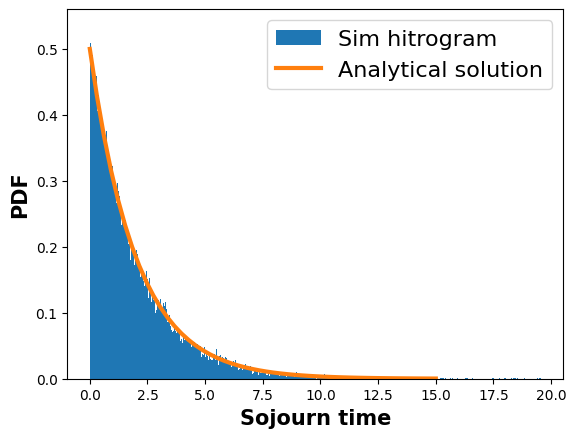

In [13]:
plt.figure()
plt.hist(queue_example.sojourn_time, density = True, bins =1000, label = 'Sim hitrogram')
plt.plot(x_vals, S, lw = 3, label = 'Analytical solution')
plt.legend(fontsize = 16)
plt.xlabel('Sojourn time',fontweight="bold", fontsize = 15)
plt.ylabel('PDF',fontweight="bold", fontsize = 15)
plt.show()

<div dir="rtl">


## נראה שזמן שהייה בסימולציה מתארים היטב את ההתפלגות האמיתית
    
### נחשב זמני המתנה ממוצע וזמני שהייה ממוצעים: 

<div dir="rtl">
    
### ידוע כי זמן שהיה הוא בעצם זמן המתנה ועוד זמן שירות. נניח כי $\bar{S}$ זה תוחלת זמן שהייה $\bar{W}$ תוחלת זמן המתנה ו-$\bar{X}$ תוחלת זמן שירות
    
### לכן:
    
$$ \bar{S} = \bar{X}+\bar{W} $$

In [14]:
## Sojourn

S_avg = np.array(queue_example.sojourn_time).mean()

## Waiting

W_avg = np.array(queue_example.waiting_time).mean()

X_avg = 1/mu

S_avg, W_avg, X_avg

(np.float64(1.9722906973536316), np.float64(1.473384332857459), 0.5)

In [15]:
W_avg+X_avg, S_avg

(np.float64(1.973384332857459), np.float64(1.9722906973536316))

<div dir="rtl">

#### נראה שהערכים זהים פחות או יותר
    
### נניח נרצה לדעת את הסיכוי שצרכן ישהה במערכת יותר מ-2 דקות. פורמלית: 
    
### $$ P(W>2)? $$
    
#### פשוט נראה מהי השכיחות היחסית של הצרכנים ששהו במערכת יותר מ-2 דקות. חישוב פשוט numpy:

In [16]:
sojourn_arr = np.array(queue_example.sojourn_time)

(sojourn_arr>2).mean()

np.float64(0.3618886475972235)

<div dir="rtl">

### תיאורטית זה צריך להיות כי יודעים את ההתפלגות של זמן שהייה: 

In [17]:
np.exp(-0.5*2)

np.float64(0.36787944117144233)

<div dir="rtl">

    
### נניח נרצה לחשב סטיית תקן של זמן שהייה במערכת
    
### במקרה זה, ניקח את זמני השהייה ונבקש עבור המערך הזה לחשב סטיית תקן

In [19]:
sojourn_arr.std()

np.float64(1.9962484577737238)

<div dir="rtl">

### כאן אנחנו מחשבים לא רק תוחלת אלא התפלגות. זה מידע יותר מורכב 

<div dir="rtl">

### Computing $L$ distribution

#### למעלה חישבנו זמני שהייה והמתנה. כיצד נחשב התפלגות מספר צרכנים במערכת?
    
#### נניח שאתם אורחים מזדמנים במפעל. יש במפעל מכונה וחצי מהזמן היא עובדת וחצי מהזמן היא בבטלה. מה הסיכוי שרגע הגעתכם המכונה בבטלה? 
    
#### תשובה: 0.5
    
#### נניח כי יש למכונה 3 אפשרויות - בטלה, אחזקה ועובדת. עכשיו ראיתם שבשנה האחרונה 3000 שעות המכונה הייתה בבטלה, 4000 שעות המכונה הייתה באחזקה ו-2000 שעות המכונה עבדה

    
#### מה ההסתברות שבביקור מזדמן המכונה עבדה?
    
### $$ P(Working) = \frac{2000}{2000+3000+4000} = \frac{2000}{9000} = \frac{2}{9} $$
    
####  באופן דומה נחשב את התפלגות מספר הצרכנים במערכת. נראה כמה זמן היה סה"כ כל מספר אפשרי של צרכנים וההסבתרות תהיה החלק היחסי.
    
#### למשל: נניח הרצתי סימולציה 100 שעות, ובמשך שעה סה"כ היו שלושה צרכנים אז ההסתברות ל-3 שלושה צרכנים היא 0.01.
    
### הרעיון הכללי כל פעם שיש שינוי במספר הצרכנים במערכת נבדוק כמה זמן עבר ונשייך את הזמן הזה לאותה כמות צרכנים.

### למשל אם בזמן 0 היו 3 צרכנים במערכת. 

### נניח כי השתנה ב1.2 כאשר הייתה הגעה. אז בעצם היו 3 צרכנים למשך 1.2 יחידות זמן. כל פעם שיהיו 3 צרכנים במערכת נצבור את הזמן הכולל יחד עם ה1.2 שכבר היה. 

In [16]:
num_cust_durations = np.zeros(500)

num_cust_durations[:5]

array([0., 0., 0., 0., 0.])

In [20]:
is_print = False

class Queue_example1:

    def __init__(self, lamda, mu, sim_time):

        self.env = simpy.Environment() # initializing simpy enviroment 
        self.server = simpy.Resource(self.env, capacity=1) # Defining a resource with capacity 1
        self.end_time = sim_time # The time simulation terminate
        self.id_current = 0 # keeping track of cusotmers id
        #an event can one of three: (1. arrival, 2. entering service 3. service completion)
        
        self.print = False
        self.mu = mu # service rate
        self.lamda = lamda # inter-arrival rate
        
        ### L computation
        self.num_cust_durations = np.zeros(500) ## the time duration of each each state (state= number of cusotmers in the system)
        self.last_event_time = 0 # the time of the last event - 
        self.num_cust_sys = 0 # keeping track of number of customers in the system


    def run(self):

        self.env.process(self.customer_arrivals()) ## Initializing a process
        self.env.run(until=self.end_time) ## Running the simulaiton until self.end_time

    
    
    #########################################################
    ################# Service block ######################### 
    ######################################################### 
    
    
    def service(self, id_customer):

        arrival_time = self.env.now
        
        with self.server.request() as req:
                       
            yield req
            
            yield self.env.timeout(np.random.exponential(1/self.mu))
            
            print('Customer {} complete service at {}'.format(id_customer, self.env.now))
                
            ###################################
            ### Tracking number of customers ##
            ###################################
            
            ########## Computing the time that elapsed since the last event ###############
            tot_time = self.env.now - self.last_event_time  # keeping track of the last event
            
            ###@@@@@@@@@@@@@############## Accumilating the time that the system was under self.num_cust_sys
            self.num_cust_durations[self.num_cust_sys] += tot_time # Since the number of customers in the system changes
            
             ###@@@@@@@@@@@@@###############
            print('Num cust duration', self.num_cust_durations[:5])
            if self.print:
                print(tot_time, self.num_cust_sys)
                
            #we compute how much time the system had this number of customers   
            self.num_cust_sys -= 1 # updating number of cusotmers in the system
            self.last_event_time = self.env.now
            print('number in the system {} last_event_time {}' .format(self.num_cust_sys , self.last_event_time))
            
            ###################################
            ###################################
            ###################################            

    #########################################################
    ################# Arrival block ######################### 
    ######################################################### 
    
    
    def customer_arrivals(self):

        while True:

            yield self.env.timeout(np.random.exponential(1/self.lamda))

            self.id_current += 1
            
            id_customer = self.id_current
            
            print('Customer {} arrived at {}'.format(id_customer, self.env.now))
            
            ###################################
            ### Tracking number of customers ##
            ###################################

            ########## Computing the time that elapsed since the last event ###############
            tot_time = self.env.now - self.last_event_time
            
            ###@@@@@@@@@@@@@############## Accumilating the time that the system was under self.num_cust_sys
            self.num_cust_durations[self.num_cust_sys] += tot_time
            
            print('Num cust duration', self.num_cust_durations[:5])

            
            if self.print:
                print(tot_time, self.num_cust_sys)
            self.num_cust_sys += 1
            self.last_event_time = self.env.now
            
            print('number in the system {} last_event_time {}' .format(self.num_cust_sys , self.last_event_time))
            
            ###################################
            ###################################
            ###################################

            self.env.process(self.service(id_customer))


In [31]:
sim_time = 2000
lamda  = 1
mu = 2

queue_example1 = Queue_example1(lamda, mu, sim_time )
queue_example1.run()

Customer 1 arrived at 0.9327077191717515
Num cust duration [0.93270772 0.         0.         0.         0.        ]
number in the system 1 last_event_time 0.9327077191717515
Customer 1 complete service at 1.2571504414195869
Num cust duration [0.93270772 0.32444272 0.         0.         0.        ]
number in the system 0 last_event_time 1.2571504414195869
Customer 2 arrived at 1.9039479389844307
Num cust duration [1.57950522 0.32444272 0.         0.         0.        ]
number in the system 1 last_event_time 1.9039479389844307
Customer 3 arrived at 1.9976502336237425
Num cust duration [1.57950522 0.41814502 0.         0.         0.        ]
number in the system 2 last_event_time 1.9976502336237425
Customer 2 complete service at 2.469541033194422
Num cust duration [1.57950522 0.41814502 0.4718908  0.         0.        ]
number in the system 1 last_event_time 2.469541033194422
Customer 3 complete service at 2.9376936972248306
Num cust duration [1.57950522 0.88629768 0.4718908  0.         0



### כדי לבדוק את התפלגות מספר הצרכנים במערכת ניקח את סה"כ הזמן שהצטבר לפי מספםר הצרכנים במערכת ונחלק בזמן הכולל.

### זה יהיה פרופורציית הזמן שהמערכת הייתה בכל מצב - זה למעשה ההסתברות שבזמן אקראי המערכת תהיה במצב כזה

In [32]:
## Converting time durations to the distribution
L_dist = queue_example1.num_cust_durations/queue_example1.num_cust_durations.sum()

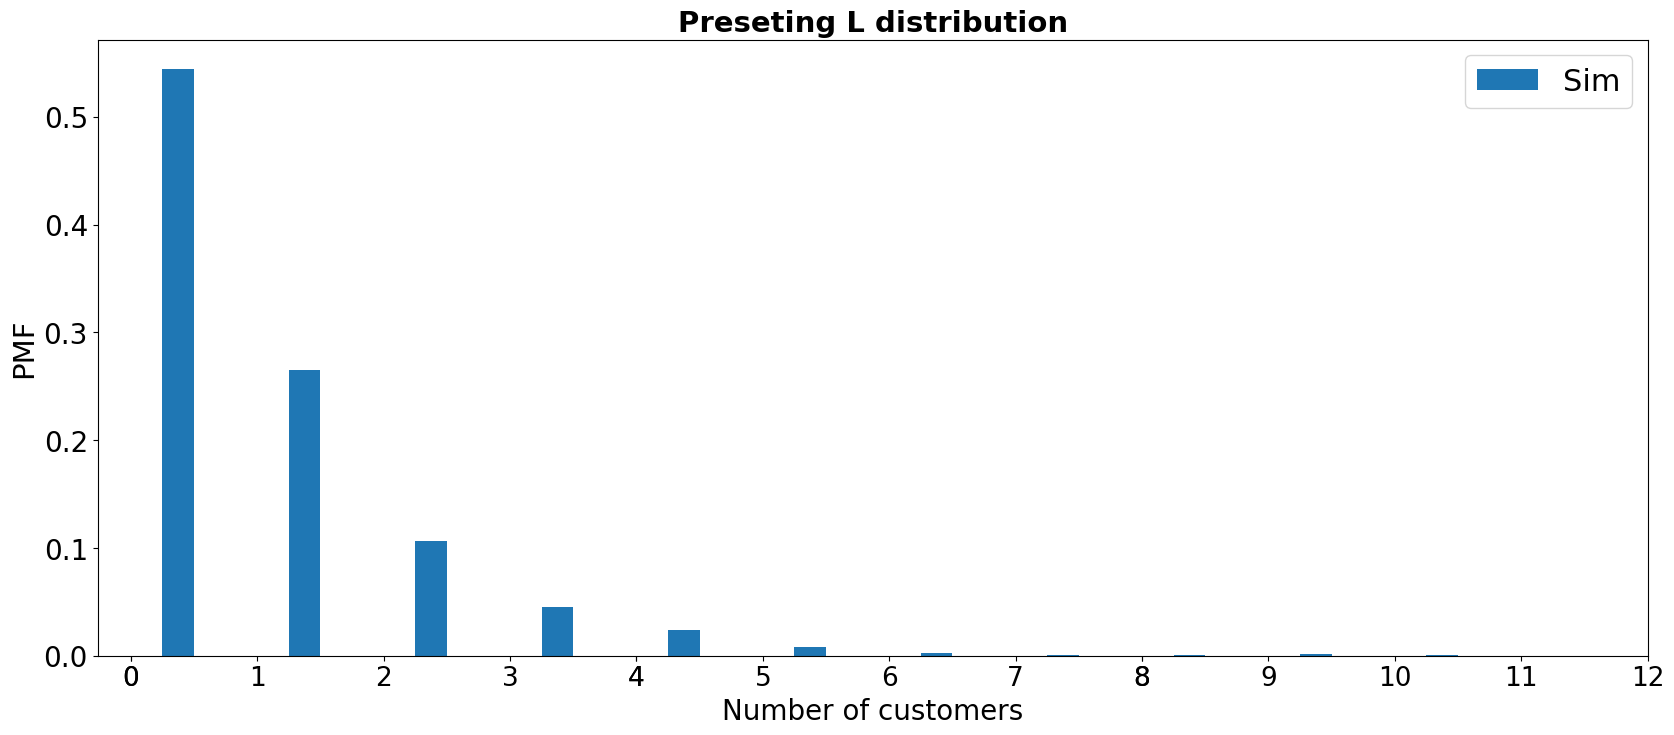

In [33]:
## Plotting the graph

fig, (ax1) = plt.subplots(1, 1, figsize=(20, 8))
width = 0.25
max_probs = 11
rects1 = ax1.bar(1.5*width+np.arange(max_probs), L_dist[:11], width, label='Sim')
plt.rcParams['font.size'] = '20'

# # Add some text for labels, title and custom x-axis tick labels, etc.
ax1.set_ylabel('PMF', fontsize=21)
ax1.set_xlabel('Number of customers', fontsize=20)
ax1.set_title( 'Preseting L distribution' , fontsize=21, fontweight="bold")
ax1.set_xticks(np.linspace(0,12,16).astype(int))
ax1.set_xticklabels(np.linspace(0,12,16).astype(int), fontsize=19)
ax1.legend(fontsize=22)
plt.show()

In [34]:
def mm1_steady(rho):
    x = np.arange(500)
    return (1-rho)*rho**x
# Extracting the ground truth
ground_truth = mm1_steady(lamda/mu)
#Computing the error
error = np.abs(L_dist[:11] - ground_truth[:11])

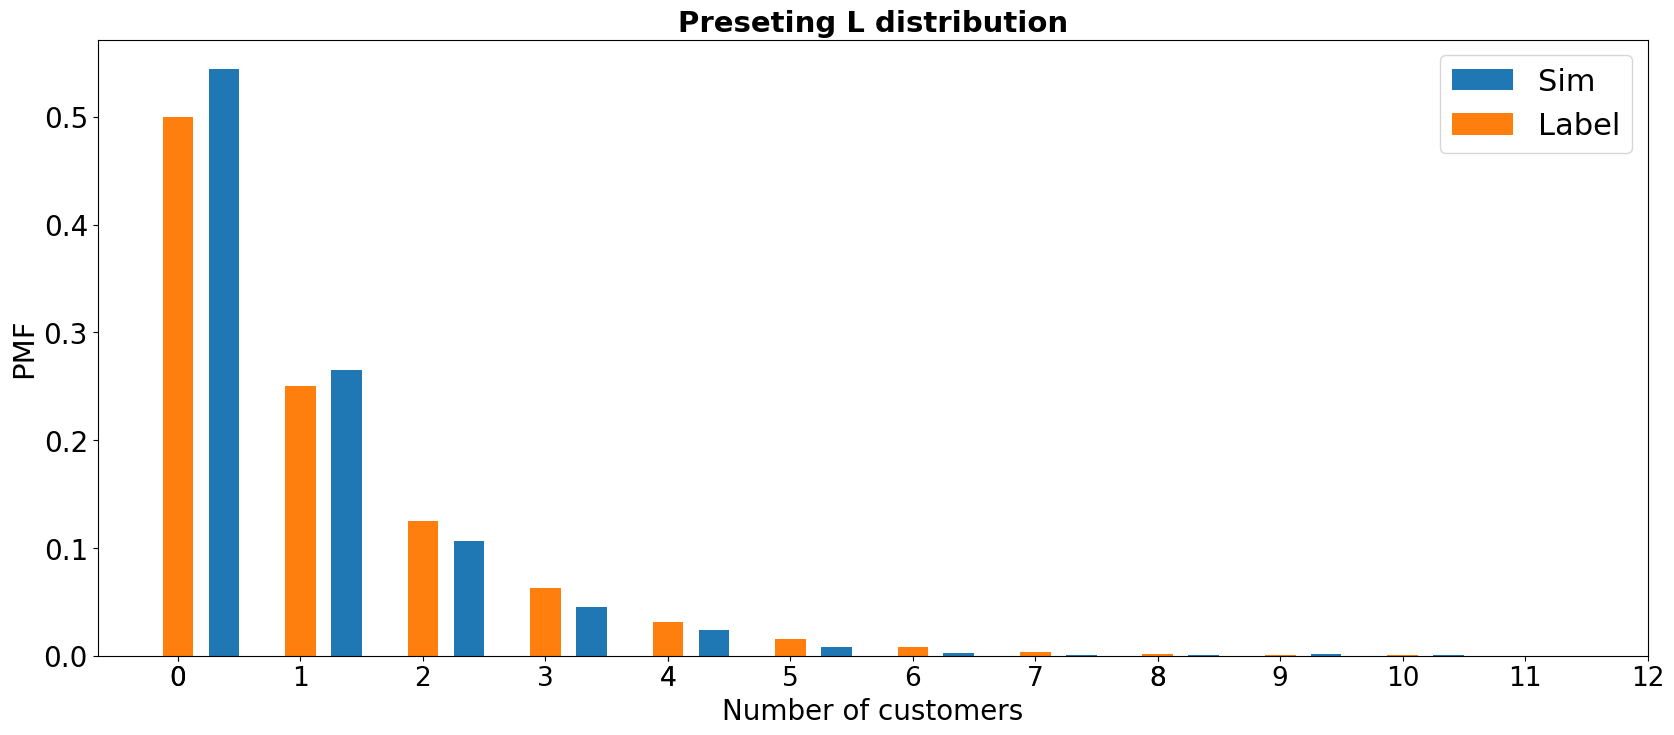

In [35]:
## Plotting the graph

fig, (ax1) = plt.subplots(1, 1, figsize=(20, 8))
width = 0.25
max_probs = 11
rects1 = ax1.bar(1.5*width+np.arange(max_probs), L_dist[:11], width, label='Sim')
rects2 = ax1.bar(np.arange(max_probs) , ground_truth[:11], width, label='Label')
plt.rcParams['font.size'] = '20'

# # Add some text for labels, title and custom x-axis tick labels, etc.
ax1.set_ylabel('PMF', fontsize=21)
ax1.set_xlabel('Number of customers', fontsize=20)
ax1.set_title( 'Preseting L distribution' , fontsize=21, fontweight="bold")
ax1.set_xticks(np.linspace(0,12,16).astype(int))
ax1.set_xticklabels(np.linspace(0,12,16).astype(int), fontsize=19)
ax1.legend(fontsize=22)
plt.show()

### How was error computed?

### We use Total Variation (TV) measure:

* $P_i^{label}$ the probability of having $i$ customers based on the exact analytical solution
* $P_i^{sim}$ the probability of having $i$ customers based on simulation

$$ TV = \frac{1}{2}\sum_{i \geq 0} |P_i^{label}-P_i^{sim}|$$




<div dir="rtl">

### המדד זה נותן את השגיאה המקסימלית האפשרית עבור כל ערך

## ניתוח של המערכת כולה או תת מערכת
    
### נניח שאני רוצה לנתח חלק מהמערכת ולא רק תור בודד. כיצד  עלי לעשות זאת?
    
#### למשל - נניח כי אני רוצה לחשב בחדר מיון התפלגות זמן שהייה של כל המערכת. 

In [36]:
class Queue_ED:

    def __init__(self, lamda, mu_reception, mu_nurse, mu_acu_doctor, mu_ed_doctor, sim_time):

           # Defining a simpy envirment
        self.env = simpy.Environment()
        # Attaching a server to a simpy envirment
        self.nurse = simpy.Resource(self.env, capacity=1)
        self.reception = simpy.Resource(self.env, capacity=1)
        self.ed_doctor = simpy.Resource(self.env, capacity=1)
        self.acu_doctor = simpy.Resource(self.env, capacity=1)

        self.id_customer = 0 # keeping track of cusotmers id
        #an event can one of three: (1. arrival, 2. entering service 3. service completion)
        
        self.print = False
        
        self.mu_reception = mu_reception # service rate
        self.mu_nurse = mu_nurse # service rate
        self.mu_acu_doctor = mu_acu_doctor # service rate
        self.mu_ed_doctor = mu_ed_doctor
        self.lamda = lamda # inter-arrival rate
        
        
        self.last_event_time = 0 # the time of the last event - 
        self.num_cust_sys = 0 # keeping track of number of customers in the system
        self.end_time = sim_time
        self.sojorun_entire_system = []

    def run(self):

        self.env.process(self.customer_arrivals()) ## Initializing a process
        self.env.run(until=self.end_time) ## Running the simulaiton until self.end_time


    #########################################################
    ###################  Arrival block ###################### 
    #########################################################

    def customer_arrivals(self):


        while True:

            self.id_customer += 1

            # Timeout means the time span bewteen two arrivals
            yield self.env.timeout(np.random.exponential(1/self.lamda))
            
            if self.print:
            
                print('Customer {} arrived at time: {}' .format(self.id_customer, self.env.now))

            self.env.process(self.service(self.id_customer))

    #########################################################
    ###################  Service block ###################### 
    #########################################################

    def service(self, id_customer):
        
        ## For tracking the arrival time of customer
        arrival_time = self.env.now

        ################
        ## Reception ###
        ################

        with self.reception.request() as req:
            
            ## Requesting a server
            yield req
            
            if self.print:
                print('Customer {} start reception service  at time: {}' .format(id_customer, self.env.now))
            # if server if available service will be granted.

            # Timeout means the time span bewteen a single service
            yield self.env.timeout(np.random.exponential(1/self.mu_reception))
            if self.print:
                print('Customer {} complete reception service  at time: {}' .format(id_customer, self.env.now))

        ################
        ## Nurse     ###
        ################

        with self.nurse.request() as req:

            ## Requesting a server
            yield req
            if self.print:
                print('Customer {} start nurse service  at time: {}' .format(id_customer, self.env.now))
            # if server if available service will be granted.

            # Timeout means the time span bewteen a single service
            yield self.env.timeout(np.random.exponential(1/self.mu_nurse))
            
            if self.print:
                print('Customer {} complete nurse service  at time: {}' .format(id_customer, self.env.now))

        ## a random number between 0 to 1
        random_decision = np.random.rand()



        if random_decision < 0.8:

            ################
            ## acu doctor ##
            ################

            with self.acu_doctor.request() as req:

                ## Requesting a server
                yield req
                if self.print:
                    print('Customer {} start acu_doctor service  at time: {}' .format(id_customer, self.env.now))
                # if server if available service will be granted.

                # Timeout means the time span bewteen a single service
                yield self.env.timeout(np.random.exponential(1/self.mu_acu_doctor))
                if self.print:
                    print('Customer {} complete acu_doctor service  at time: {}' .format(id_customer, self.env.now))
                    

        else:

            ################
            ## ed  doctor ##
            ################

            with self.ed_doctor.request() as req:

                ## Requesting a server
                yield req
                if self.print:
                    print('Customer {} start ed_doctor service  at time: {}' .format(id_customer, self.env.now))
                # if server if available service will be granted.

                # Timeout means the time span bewteen a single service
                yield self.env.timeout(np.random.exponential(1/self.mu_ed_doctor))
                
                if self.print:
                    print('Customer {} complete ed_doctor service  at time: {}' .format(id_customer, self.env.now))

        ## Customer leaves the system
        self.sojorun_entire_system.append(self.env.now-arrival_time)


In [37]:
## Model input

mu_reception = 2
mu_nurse = 1.5
mu_ed_doctor = 1.8
mu_acu_doctor = 0.9
lamda = 1
end_time = 250000

queue_ED = Queue_ED(lamda, mu_reception, mu_nurse, mu_acu_doctor, mu_ed_doctor,  end_time )
queue_ED.run()

In [38]:
### Customer left the system 

np.array(queue_ED.sojorun_entire_system).mean()

np.float64(10.916254236246726)

In [39]:
class Queue_ED:

    def __init__(self, lamda, mu_reception, mu_nurse, mu_acu_doctor, mu_ed_doctor, sim_time):

           # Defining a simpy envirment
        self.env = simpy.Environment()
        # Attaching a server to a simpy envirment
        self.nurse = simpy.Resource(self.env, capacity=1)
        self.reception = simpy.Resource(self.env, capacity=1)
        self.ed_doctor = simpy.Resource(self.env, capacity=1)
        self.acu_doctor = simpy.Resource(self.env, capacity=1)

        self.id_customer = 0 # keeping track of cusotmers id
        #an event can one of three: (1. arrival, 2. entering service 3. service completion)
        
        self.print = False
        
        self.mu_reception = mu_reception # service rate
        self.mu_nurse = mu_nurse # service rate
        self.mu_acu_doctor = mu_acu_doctor # service rate
        self.mu_ed_doctor = mu_ed_doctor
        self.lamda = lamda # inter-arrival rate
        
        
        self.last_event_time = 0 # the time of the last event - 
        self.num_cust_sys = 0 # keeping track of number of customers in the system
        self.end_time = sim_time
        self.sojorun_entire_system = []

    def run(self):

        self.env.process(self.customer_arrivals()) ## Initializing a process
        self.env.run(until=self.end_time) ## Running the simulaiton until self.end_time


    #########################################################
    ###################  Arrival block ###################### 
    #########################################################

    def customer_arrivals(self):


        while True:

            self.id_customer += 1

            # Timeout means the time span bewteen two arrivals
            yield self.env.timeout(np.random.exponential(1/self.lamda))
            
            if self.print:
            
                print('Customer {} arrived at time: {}' .format(self.id_customer, self.env.now))

            self.env.process(self.service(self.id_customer))

    #########################################################
    ###################  Service block ###################### 
    #########################################################

    def service_zutar(self, id_customer):
        
        ## For tracking the arrival time of customer
        arrival_time = self.env.now

        ################
        ## Reception ###
        ################

        with self.reception.request() as req:
            
            ## Requesting a server
            yield req
            
            if self.print:
                print('Customer {} start reception service  at time: {}' .format(id_customer, self.env.now))
            # if server if available service will be granted.

            # Timeout means the time span bewteen a single service
            yield self.env.timeout(np.random.exponential(1/self.mu_reception))
            if self.print:
                print('Customer {} complete reception service  at time: {}' .format(id_customer, self.env.now))
            p12 = 0.2
            if np.random.rand() < p12:
                self.env.process(self.service_senior(self.id_customer))
        ################
        ## Nurse     ###
        ################
    def service_senior(self, id_customer):
        
        with self.nurse.request() as req:

            ## Requesting a server
            yield req
            if self.print:
                print('Customer {} start nurse service  at time: {}' .format(id_customer, self.env.now))
            # if server if available service will be granted.

            # Timeout means the time span bewteen a single service
            yield self.env.timeout(np.random.exponential(1/self.mu_nurse))
            if np.random.rand() < p23:
                self.env.process(self.service_incharge(self.id_customer))
            if self.print:
                print('Customer {} complete nurse service  at time: {}' .format(id_customer, self.env.now))

        ## a random number between 0 to 1
        random_decision = np.random.rand()

    def service_incharge(self, id_customer):

       

        ################
        ## acu doctor ##
        ################

        with self.acu_doctor.request() as req:

            ## Requesting a server
            yield req
            if self.print:
                print('Customer {} start acu_doctor service  at time: {}' .format(id_customer, self.env.now))
            # if server if available service will be granted.

            # Timeout means the time span bewteen a single service
            yield self.env.timeout(np.random.exponential(1/self.mu_acu_doctor))
            if self.print:
                print('Customer {} complete acu_doctor service  at time: {}' .format(id_customer, self.env.now))
                    

        
        ## Customer leaves the system
        self.sojorun_entire_system.append(self.env.now-arrival_time)
